# 01b – Torquemeter through the year, with operating mode

The overview figure from `01_propulsion.ipynb`, extended so the faults can be **compared with what the ship was doing**: sailing, in port, at anchor.

**Unlike the figure in 01, this uses all moments, not only sailing.** In port the power should be about 0, so the comparison shows whether a fault happens at sea (a real problem) or only in port (less important).

How to read it:
- **Two ribbons on top:** what the ship was doing (operating mode) and when the torquemeter was faulty, hour by hour.
- **Background colour in every panel:** the same operating mode, so each value can be read against it.
- **Dashed lines:** steps in fuel per kWh (see 01 §6d).

Operating modes come from `src/trust.py` (`operating_mode`): a stop is SOG below 0.5 kn for at least 2 h; **port** if the heading stays fixed (moored), **anchor** if the ship swings.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

sys.path.insert(0, os.path.join("..", "..", "src"))
import trust as T

SIG = ["shaft_kw", "shaft_rpm", "shaft_torque_nm", "thrust_kn", "shaft_kwh", "shaft_revs", "fo_kgh",
       "me_rpm", "me_load_pct", "me_scav_bar", "me_tc_rpm_tr", "sog_kn", "stw_kn", "heading_deg"]
w = T.load_wide(SIG, name="propulsion")          # same cache as 01_propulsion
mode = T.operating_mode(w)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, DARK = "#1f1f1e", "#6b6a64", "#e6e5e0", "#4a4a46"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10})

MODE_COLORS = {"port": BLUE, "anchor": AQUA, "port, propeller turning": YELLOW, "unknown": "#c9c8c1"}   # sailing = no colour
FAULT_COLORS = {"torquemeter reads 0 (dropout)": "#7a7972", "torquemeter negative (sign fault)": ORANGE}

tm_zero = (w.me_rpm > 50) & (w.shaft_rpm.abs() < 1) & (w.shaft_kw.abs() < 50) & (w.shaft_torque_nm.abs() < 5)
sign_fault = (w.shaft_rpm < -5) & (w.me_rpm > 5)
fault = pd.Series("", index=w.index)
fault[tm_zero] = "torquemeter reads 0 (dropout)"
fault[sign_fault] = "torquemeter negative (sign fault)"

def hourly_label(s):
    """Most common label per hour (empty string = none)."""
    return s.groupby(s.index.floor("1h")).agg(lambda x: x.value_counts().idxmax())

mode_h = hourly_label(mode)
fault_h = hourly_label(fault)
print("hours per operating mode:"); print(mode_h.value_counts().to_string())

hours per operating mode:
sailing    7054
port        939
anchor      748
unknown     241


## Faults per operating mode

How many hours of each fault fall in each mode. Faults at sea matter most, because that is the data the models use.

In [2]:
tab = pd.crosstab(fault_h.replace("", "no fault").rename("fault"), mode_h.rename("operating mode"),
                  margins=True, margins_name="total")
tab

operating mode,anchor,port,sailing,unknown,total
fault,,,,,
no fault,748,939,6280,241,8208
torquemeter negative (sign fault),0,0,118,0,118
torquemeter reads 0 (dropout),0,0,656,0,656
total,748,939,7054,241,8982


## Figure

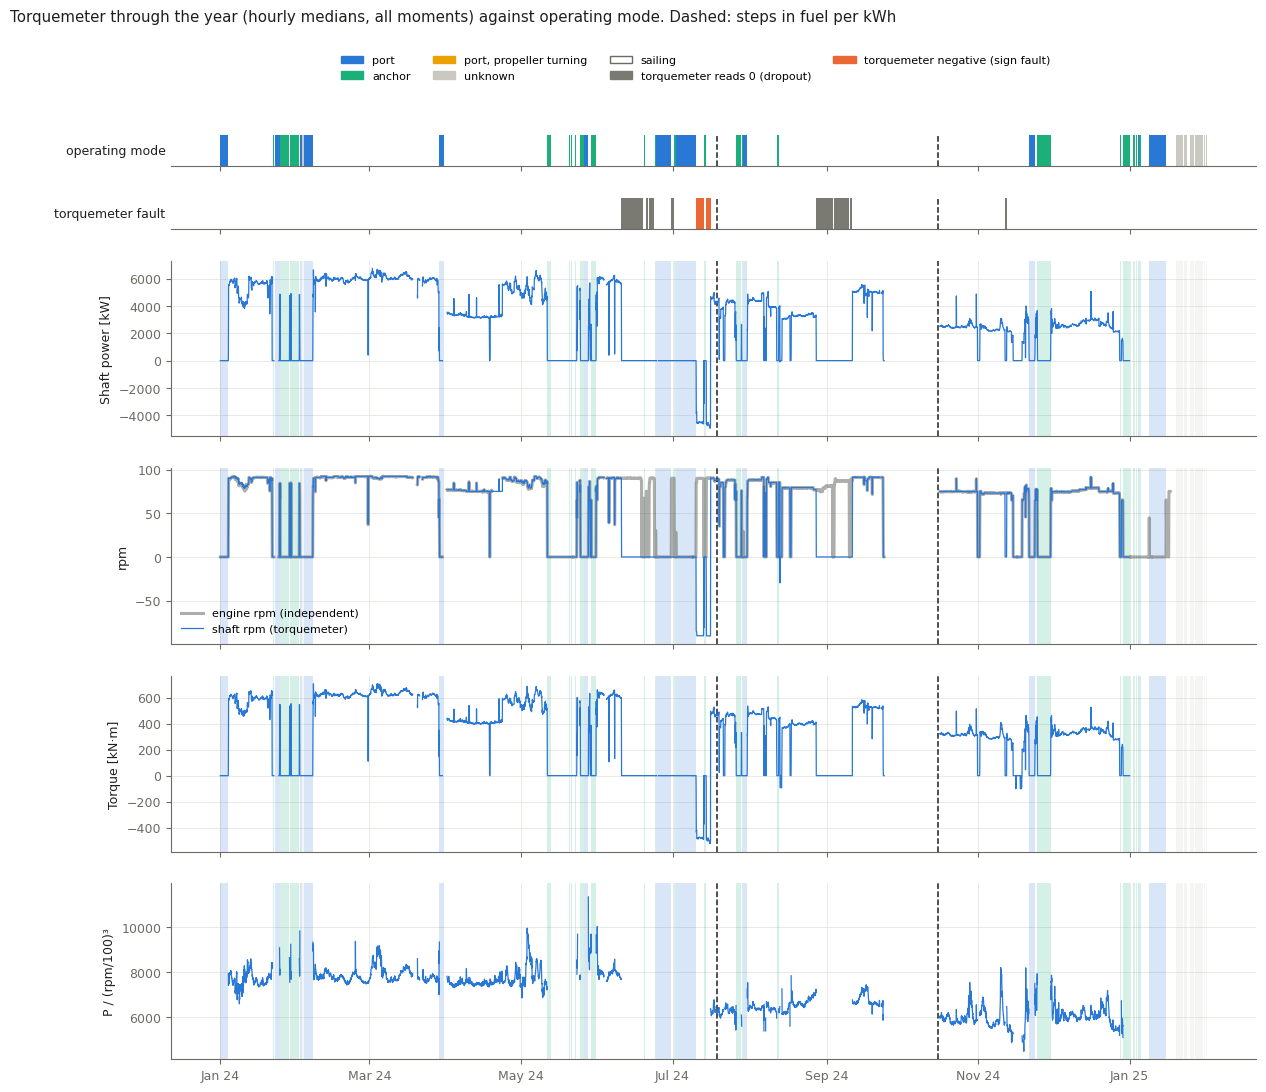

In [3]:
h = w.resample("1h").median()
kk = (w.shaft_kw / (w.shaft_rpm / 100) ** 3).where((w.shaft_rpm > 60) & (w.shaft_kw > 1000)).resample("1h").median()
running = (mode == "sailing") & (w.me_rpm > 30)
sfoc = T.daily((1000 * w.fo_kgh / w.shaft_kw).where(running & (w.shaft_kw > 2000) & (w.fo_kgh > 200)), "median")
steps = T.find_steps(sfoc)

def spans(labels):
    """Yield (start, end, label) for unbroken runs of the same hourly label."""
    lab = labels.reindex(pd.date_range(labels.index.min(), labels.index.max(), freq="1h"))
    grp = (lab != lab.shift()).cumsum()
    for _, g in lab.groupby(grp):
        if isinstance(g.iloc[0], str) and g.iloc[0]:
            yield g.index[0], g.index[-1] + pd.Timedelta("1h"), g.iloc[0]

mode_spans = list(spans(mode_h))
fault_spans = list(spans(fault_h))

fig = plt.figure(figsize=(14, 12))
gs = fig.add_gridspec(6, 1, height_ratios=[0.35, 0.35, 2, 2, 2, 2], hspace=0.25)
ax_mode = fig.add_subplot(gs[0]); ax_fault = fig.add_subplot(gs[1], sharex=ax_mode)
axes = [fig.add_subplot(gs[i], sharex=ax_mode) for i in range(2, 6)]

for ax, sp, colors, name in [(ax_mode, mode_spans, MODE_COLORS, "operating mode"),
                             (ax_fault, fault_spans, FAULT_COLORS, "torquemeter fault")]:
    for a, b, lab in sp:
        if lab in colors:
            ax.axvspan(a, b, color=colors[lab], lw=0)
    ax.set_yticks([]); ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    ax.grid(False); ax.spines["left"].set_visible(False)
    plt.setp(ax.get_xticklabels(), visible=False)

panels = [
    ("Shaft power [kW]", [(h.shaft_kw, BLUE, "shaft power")]),
    ("rpm", [(h.me_rpm, DARK, "engine rpm (independent)"), (h.shaft_rpm, BLUE, "shaft rpm (torquemeter)")]),
    ("Torque [kN·m]", [(h.shaft_torque_nm, BLUE, "torque")]),
    ("P / (rpm/100)³", [(kk, BLUE, "power ÷ rpm³")]),
]
for ax, (ylab, series) in zip(axes, panels):
    for a, b, lab in mode_spans:
        if lab in MODE_COLORS:
            ax.axvspan(a, b, color=MODE_COLORS[lab], alpha=0.18, lw=0)
    for ser, col, lab in series:
        thick = col == DARK
        ax.plot(ser.index, ser, color=col, lw=2.2 if thick else 0.9, alpha=0.45 if thick else 1, label=lab,
                zorder=2 if thick else 3)
    ax.set_ylabel(ylab)
    if len(series) > 1:
        ax.legend(frameon=False, loc="lower left", fontsize=8)
for ax in [ax_mode, ax_fault] + axes:
    for _, s_ in steps.iloc[1:].iterrows():
        ax.axvline(pd.Timestamp(s_["from"]), color=INK, ls="--", lw=1.1)
for ax in axes[:-1]:
    plt.setp(ax.get_xticklabels(), visible=False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

handles = [Patch(color=c, label=l) for l, c in MODE_COLORS.items()] + [Patch(facecolor="white", edgecolor=MUTED, label="sailing")] \
        + [Patch(color=c, label=l) for l, c in FAULT_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 0.955))
fig.suptitle("Torquemeter through the year (hourly medians, all moments) against operating mode. Dashed: steps in fuel per kWh",
             x=0.01, y=0.985, ha="left", color=INK)
plt.show()

## Zoom: one month

Change `START` and `END` to look at any period in detail, e.g. the June dropouts or the July sign fault.

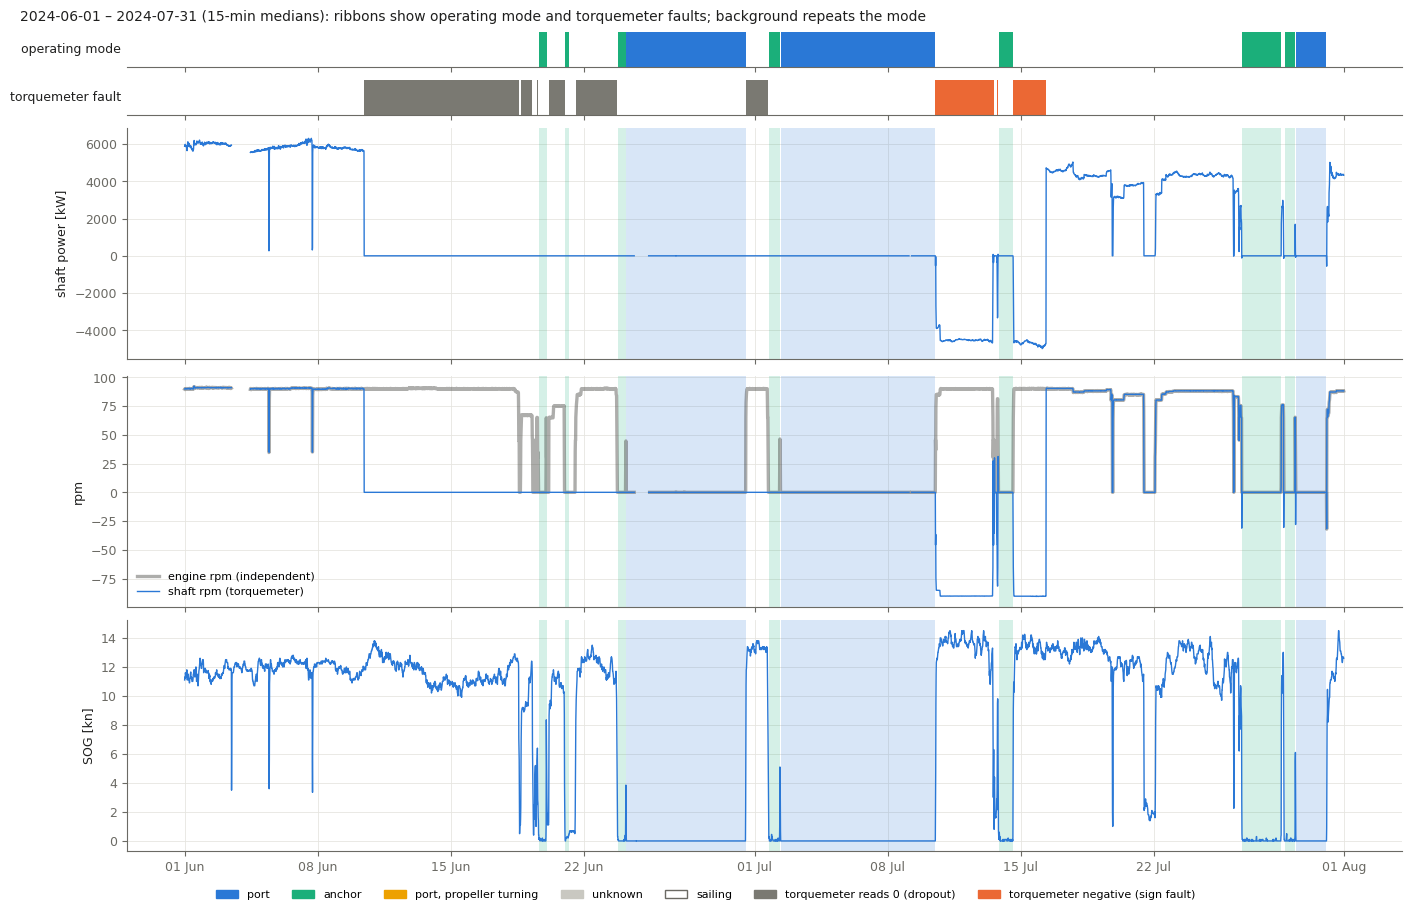

In [4]:
START, END = "2024-06-01", "2024-07-31"
z = w.loc[START:END]
zh = z.resample("15min").median()
zm_spans = list(spans(hourly_label(mode.loc[START:END])))
zf_spans = list(spans(hourly_label(fault.loc[START:END])))

fig = plt.figure(figsize=(14, 9), layout="constrained")
gs = fig.add_gridspec(5, 1, height_ratios=[0.3, 0.3, 2, 2, 2])
r_mode = fig.add_subplot(gs[0]); r_fault = fig.add_subplot(gs[1], sharex=r_mode)
axes = [fig.add_subplot(gs[i], sharex=r_mode) for i in range(2, 5)]
for ax, sp, colors, name in [(r_mode, zm_spans, MODE_COLORS, "operating mode"), (r_fault, zf_spans, FAULT_COLORS, "torquemeter fault")]:
    for a, b, lab in sp:
        if lab in colors:
            ax.axvspan(a, b, color=colors[lab], lw=0)
    ax.set_yticks([]); ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    ax.grid(False); ax.spines["left"].set_visible(False)
    plt.setp(ax.get_xticklabels(), visible=False)
for ax in axes:
    for a, b, lab in zm_spans:
        if lab in MODE_COLORS:
            ax.axvspan(a, b, color=MODE_COLORS[lab], alpha=0.18, lw=0)
axes[0].plot(zh.index, zh.shaft_kw, color=BLUE, lw=1); axes[0].set_ylabel("shaft power [kW]")
axes[1].plot(zh.index, zh.me_rpm, color=DARK, lw=2.4, alpha=0.45, label="engine rpm (independent)", zorder=2)
axes[1].plot(zh.index, zh.shaft_rpm, color=BLUE, lw=1, label="shaft rpm (torquemeter)", zorder=3)
axes[1].set_ylabel("rpm"); axes[1].legend(frameon=False, loc="lower left", fontsize=8)
axes[2].plot(zh.index, zh.sog_kn, color=BLUE, lw=1); axes[2].set_ylabel("SOG [kn]")
for ax in axes[:-1]:
    plt.setp(ax.get_xticklabels(), visible=False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.legend(handles=handles, loc="outside lower center", ncol=7, frameon=False, fontsize=8)
fig.suptitle(f"{START} – {END} (15-min medians): ribbons show operating mode and torquemeter faults; background repeats the mode",
             x=0.01, ha="left", color=INK, fontsize=10)
plt.show()

## Evidence: the torquemeter is dead, but the engine runs and the ship sails

One dropout up close: **10 Jun 2024, 10:40**. Four panels from three independent instruments:

1. **Torquemeter:** shaft power and torque drop to exactly 0.
2–3. **Engine** (its own sensors, not the torquemeter): engine rpm and fuel flow carry on as before.
4. **Ship** (GPS): speed over ground carries on as before.

If the engine had really stopped, fuel and engine rpm would drop and the ship would slow down. They don't, so the zeros are a sensor failure, not reality. Change `T0` to look at another dropout (e.g. `"2024-08-27 20:26"`).

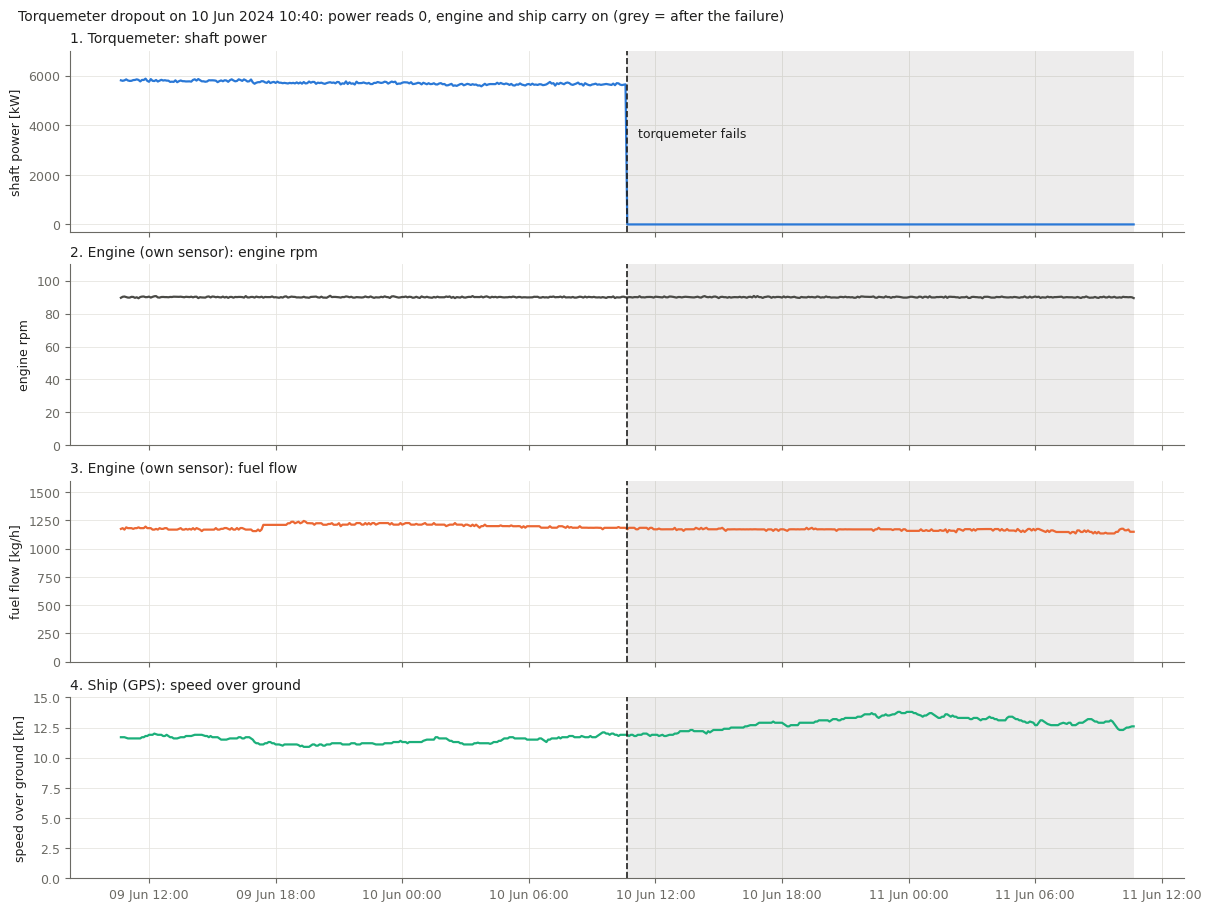

,day before (median),day after (median)
shaft power [kW],5712.5,0.0
torque [kN·m],604.4,0.0
engine rpm,90.1,90.1
fuel flow [kg/h],1199.0,1171.0
engine load [%],48.3,48.0
speed over ground [kn],11.5,12.9


In [5]:
T0 = pd.Timestamp("2024-06-10 10:40")            # moment the torquemeter fails
z = w.loc[T0 - pd.Timedelta("1D"): T0 + pd.Timedelta("1D")].resample("5min").median()

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True, layout="constrained")
panels = [
    (z.shaft_kw, BLUE, "shaft power [kW]", (-300, 7000), "1. Torquemeter: shaft power"),
    (z.me_rpm, DARK, "engine rpm", (0, 110), "2. Engine (own sensor): engine rpm"),
    (z.fo_kgh, ORANGE, "fuel flow [kg/h]", (0, 1600), "3. Engine (own sensor): fuel flow"),
    (z.sog_kn, AQUA, "speed over ground [kn]", (0, 15), "4. Ship (GPS): speed over ground"),
]
for ax, (ser, col, ylab, ylim, title) in zip(axes, panels):
    ax.plot(ser.index, ser, color=col, lw=1.6)
    ax.set_ylabel(ylab); ax.set_ylim(*ylim)
    ax.set_title(title, loc="left", color=INK)
for ax in axes:
    ax.axvspan(T0, z.index.max(), color=MUTED, alpha=0.12, lw=0)
    ax.axvline(T0, color=INK, ls="--", lw=1.2)
axes[0].annotate("torquemeter fails", xy=(T0, 3500), xytext=(8, 0), textcoords="offset points", color=INK, fontsize=9)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.suptitle(f"Torquemeter dropout on {T0:%d %b %Y %H:%M}: power reads 0, engine and ship carry on (grey = after the failure)",
             x=0.01, ha="left", color=INK, fontsize=10)
plt.show()

before = w.loc[T0 - pd.Timedelta("1D"): T0 - pd.Timedelta("15s")]
after = w.loc[T0: T0 + pd.Timedelta("1D")]
cols = {"shaft_kw": "shaft power [kW]", "shaft_torque_nm": "torque [kN·m]", "me_rpm": "engine rpm",
        "fo_kgh": "fuel flow [kg/h]", "me_load_pct": "engine load [%]", "sog_kn": "speed over ground [kn]"}
pd.DataFrame({"day before (median)": before[list(cols)].median(), "day after (median)": after[list(cols)].median()}
             ).rename(index=cols).round(1)

## Notes

**First reading (mp, 22 Oct):**
- **All torquemeter faults happen while sailing**, none in port or at anchor (table above). So they hit exactly the data the models use.
- **June–July sequence (zoom):** the torquemeter drops to 0 at sea on 10 Jun → stays at 0 through the port stay 25 Jun – 10 Jul → comes back with the **wrong sign** when the ship leaves on 10 Jul → right sign again from about 16 Jul, but reading lower than before. This looks like **work on the torquemeter during the port stay** (reinstalled, then recalibrated), matching the "recalibration" several challenge teams reported.
- **Careful with power ÷ rpm³ alone:** fouling raises it, but a **hull cleaning lowers it**, and the July drop comes right after a two-week port stay. What separates the two is fuel per kWh: a cleaning lowers fuel and power together (fuel per kWh stays flat), a sensor under-reading only lowers power (fuel per kWh jumps). It jumped +29 %, so the sensor explanation is stronger, but a cleaning in the same stay cannot be ruled out. Ask the TA for the cleaning dates (DQ-12).
- The Aug–Sep dropout also happens at sea, with no port stay before or after it.

Add your own observations below.